# Homework 2 — bazy danych i formaty plików


In [2]:
from pathlib import Path
import duckdb

DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)
(DATA_DIR / "duckdb_tmp").mkdir(exist_ok=True)

db = duckdb.connect(
    str(DATA_DIR / "homework.duckdb"),
    config={
        "memory_limit": "1GB",
        "threads": 1,
        "preserve_insertion_order": False,
        "temp_directory": str(DATA_DIR / "duckdb_tmp"),
    },
)

print("DuckDB:", duckdb.__version__)

DuckDB: 1.2.0


In [4]:
db.sql("""
CREATE TABLE stations AS
SELECT *
FROM read_csv_auto('data/stations-2023-09.csv')
""")

db.sql("DESCRIBE stations").show()

db.sql("""
SELECT *
FROM stations
LIMIT 5
""").show()

print(
    "Liczba stacji:",
    db.sql("SELECT COUNT(*) FROM stations").fetchone()[0],
)

┌─────────────┬─────────────┬─────────┬─────────┬─────────┬─────────┐
│ column_name │ column_type │  null   │   key   │ default │  extra  │
│   varchar   │   varchar   │ varchar │ varchar │ varchar │ varchar │
├─────────────┼─────────────┼─────────┼─────────┼─────────┼─────────┤
│ id          │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ code        │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ uic         │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ name_short  │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ name_medium │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ name_long   │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ slug        │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ country     │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ type        │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ geo_lat     │ DOUBLE      │ YES     │ NULL    │ NULL    │ NULL    │
│ geo_lng     │ DOUB

In [5]:
db.sql("""
CREATE TABLE distances AS
SELECT *
FROM read_csv_auto(
    'data/tariff-distances-2022-01.csv',
    nullstr = ['XXX', '?', '']
)
""")

db.sql("""
SELECT Station, AC, AH, AHP
FROM distances
LIMIT 5
""").show()

┌─────────┬───────┬───────┬───────┐
│ Station │  AC   │  AH   │  AHP  │
│ varchar │ int64 │ int64 │ int64 │
├─────────┼───────┼───────┼───────┤
│ AC      │  NULL │    82 │    83 │
│ AH      │    82 │  NULL │     1 │
│ AHP     │    83 │     1 │  NULL │
│ AHPR    │    85 │     3 │     2 │
│ AHZ     │    90 │     8 │     9 │
└─────────┴───────┴───────┴───────┘



In [6]:
db.sql("""
CREATE TABLE distances_long AS
UNPIVOT distances
ON COLUMNS(* EXCLUDE Station)
INTO NAME other_station VALUE distance
""")

db.sql("""
SELECT *
FROM distances_long
LIMIT 10
""").show()

print(
    "Liczba par:",
    db.sql("SELECT COUNT(*) FROM distances_long").fetchone()[0],
)

┌─────────┬───────────────┬──────────┐
│ Station │ other_station │ distance │
│ varchar │    varchar    │  int64   │
├─────────┼───────────────┼──────────┤
│ AC      │ AH            │       82 │
│ AC      │ AHP           │       83 │
│ AC      │ AHPR          │       85 │
│ AC      │ AHZ           │       90 │
│ AC      │ AKL           │       71 │
│ AC      │ AKM           │      188 │
│ AC      │ ALM           │       32 │
│ AC      │ ALMB          │       38 │
│ AC      │ ALMM          │       31 │
│ AC      │ ALMO          │       40 │
├─────────┴───────────────┴──────────┤
│ 10 rows                  3 columns │
└────────────────────────────────────┘

Liczba par: 158802


In [8]:
db.sql("INSTALL postgres")
db.sql("LOAD postgres")

conn_string = "host=localhost port=5433 dbname=homework user=postgres password=postgres"

db.sql(f"""
ATTACH '{conn_string}' AS pg_homework
(TYPE postgres)
""")

print("ok")

ok


In [10]:
disruption_files = [
    str(DATA_DIR / f"disruptions-{year}.csv") for year in range(2011, 2024)
]
db.read_csv(
    disruption_files,
    header=True,
    union_by_name=True,
).create_view("disruptions_source")

db.sql("""
CREATE TABLE pg_homework.public.disruptions AS
SELECT *
FROM disruptions_source
""")

print("dane zapisane poprawnie")

Error: Failed to execute query "BEGIN TRANSACTION ISOLATION LEVEL REPEATABLE READ;
CREATE TABLE "public"."disruptions"("rdt_id" BIGINT, "ns_lines" VARCHAR, "rdt_lines" VARCHAR, "rdt_lines_id" VARCHAR, "rdt_station_names" VARCHAR, "rdt_station_codes" VARCHAR, "cause_nl" VARCHAR, "cause_en" VARCHAR, "statistical_cause_nl" VARCHAR, "statistical_cause_en" VARCHAR, "cause_group" VARCHAR, "start_time" TIMESTAMP, "end_time" TIMESTAMP, "duration_minutes" BIGINT);": ERROR:  relation "disruptions" already exists


In [11]:
db.sql("""
SELECT
    EXTRACT(YEAR FROM start_time) AS year,
    COUNT(*) AS number_of_disruptions
FROM pg_homework.public.disruptions
GROUP BY year
ORDER BY year
""").show()

db.sql("""
SELECT
    (SELECT COUNT(*) FROM disruptions_source) AS source_rows,
    (SELECT COUNT(*) FROM pg_homework.public.disruptions) AS postgres_rows
""").show()

┌───────┬───────────────────────┐
│ year  │ number_of_disruptions │
│ int64 │         int64         │
├───────┼───────────────────────┤
│  2011 │                  1846 │
│  2012 │                  2074 │
│  2013 │                  2312 │
│  2014 │                  2484 │
│  2015 │                  2947 │
│  2016 │                  3031 │
│  2017 │                  4085 │
│  2018 │                  5190 │
│  2019 │                  5940 │
│  2020 │                  4450 │
│  2021 │                  4874 │
│  2022 │                  5499 │
│  2023 │                  5168 │
├───────┴───────────────────────┤
│ 13 rows             2 columns │
└───────────────────────────────┘

┌─────────────┬───────────────┐
│ source_rows │ postgres_rows │
│    int64    │     int64     │
├─────────────┼───────────────┤
│       49900 │         49900 │
└─────────────┴───────────────┘



## Konwersja danych przejazdów do Parquet

Łączymy dane z lat 2019–2025 w jeden plik Parquet z kompresją ZSTD.
Przetwarzanie odbywa się w DuckDB.

In [12]:
service_files = [
    str(
        DATA_DIR
        / (f"services-{year}.csv" if year == 2024 else f"services-{year}.csv.gz")
    )
    for year in range(2019, 2026)
]

assert all(Path(path).exists() for path in service_files)

db.read_csv(
    service_files,
    header=True,
    union_by_name=True,
).create_view("services_source")

print("dane z 2019-2025 gotowe")

dane z 2019-2025 gotowe


In [13]:
db.sql("""
COPY (SELECT * FROM services_source)
TO 'data/services-2019-2025.parquet'
(
    FORMAT PARQUET,
    COMPRESSION ZSTD,
    ROW_GROUP_SIZE 32768
)
""")

print("Parquet gotowy")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

OutOfMemoryException: Out of Memory Error: could not allocate block of size 30.5 MiB (925.1 MiB/953.6 MiB used)

In [14]:
db.sql("SET memory_limit = '2GB'")
db.sql("SET threads = 1")
db.sql("SET preserve_insertion_order = false")

print(
    "Limit pamięci:",
    db.sql("SELECT current_setting('memory_limit')").fetchone()[0],
)

Limit pamięci: 1.8 GiB


## Zabezpieczenia przed przekroczeniem RAM-u ktore wystapily podczasz labow 

In [16]:
db.sql("""
COPY (SELECT * FROM services_source)
TO 'data/services-2019-2025-v2.parquet'
(
    FORMAT PARQUET,
    COMPRESSION ZSTD,
    ROW_GROUP_SIZE 32768
)
""")

print("Parquet gotowy")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

OutOfMemoryException: Out of Memory Error: failed to allocate data of size 1.7 MiB (1.8 GiB/1.8 GiB used)

#Proba przetworzenia lat osobno ze wzgledu na problemy z pamiecia 

In [17]:
from pathlib import Path

db.sql("SET memory_limit = '2GB'")
db.sql("SET threads = 1")
db.sql("SET preserve_insertion_order = false")
db.sql("DROP VIEW IF EXISTS services_source")

parts_dir = DATA_DIR / "services_parts"
parts_dir.mkdir(exist_ok=True)

print("ok")

ok


In [18]:
for year in range(2019, 2026):
    source = DATA_DIR / (
        f"services-{year}.csv" if year == 2024 else f"services-{year}.csv.gz"
    )

    target = parts_dir / f"services-{year}.parquet"
    temporary = parts_dir / f"services-{year}.partial.parquet"
    if target.exists():
        print(f"{year}: już gotowy — pomijam", flush=True)
        continue

    if temporary.exists():
        temporary.unlink()

    print(f"{year}: rozpoczynam...", flush=True)

    db.sql(f"""
        COPY (
            SELECT *
            FROM read_csv_auto('{source.as_posix()}')
        )
        TO '{temporary.as_posix()}'
        (
            FORMAT PARQUET,
            COMPRESSION ZSTD,
            ROW_GROUP_SIZE 32768
        )
    """)

    temporary.rename(target)
    print(f"{year}: zapisany", flush=True)

2019: rozpoczynam...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

2019: zapisany
2020: rozpoczynam...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

2020: zapisany
2021: rozpoczynam...


...

2023: zapisany
2024: rozpoczynam...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

2024: zapisany
2025: rozpoczynam...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

2025: zapisany


In [19]:
yearly_files = [parts_dir / f"services-{year}.parquet" for year in range(2019, 2026)]

assert all(path.exists() for path in yearly_files)

db.sql("""
COPY (
    SELECT *
    FROM read_parquet(
        'data/services_parts/services-*.parquet',
        union_by_name = true
    )
)
TO 'data/services-2019-2025-merged.parquet'
(
    FORMAT PARQUET,
    COMPRESSION ZSTD,
    ROW_GROUP_SIZE 32768
)
""")

print("merge ok")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

merge ok


In [21]:
db.sql("""
CREATE TABLE services AS
SELECT *
FROM read_parquet('data/services-2019-2025-merged.parquet')
""")

db.sql("CHECKPOINT")

print("Tabela services utworzona")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Tabela services utworzona


In [22]:
db.sql("""
SELECT
    EXTRACT(YEAR FROM "Service:Date") AS year,
    COUNT(*) AS number_of_stops,
    COUNT(DISTINCT "Service:RDT-ID") AS number_of_services
FROM services
GROUP BY year
ORDER BY year
""").show()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

┌───────┬─────────────────┬────────────────────┐
│ year  │ number_of_stops │ number_of_services │
│ int64 │      int64      │       int64        │
├───────┼─────────────────┼────────────────────┤
│  2019 │        20773804 │            2369241 │
│  2020 │        22235137 │            2453753 │
│  2021 │        21818011 │            2352676 │
│  2022 │        22025754 │            2453625 │
│  2023 │        21239393 │            2323100 │
│  2024 │        21857914 │            2395636 │
│  2025 │        22226311 │            2402665 │
└───────┴─────────────────┴────────────────────┘



### 7.1. Liczba odjazdów z Amsterdam Centraal


In [23]:
db.sql("""
SELECT COUNT(DISTINCT "Service:RDT-ID") AS departures_from_amsterdam
FROM services
WHERE "Stop:Station code" = 'ASD'
  AND "Stop:Departure time" IS NOT NULL
  AND NOT COALESCE("Stop:Departure cancelled", false)
""").show()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

┌───────────────────────────┐
│ departures_from_amsterdam │
│           int64           │
├───────────────────────────┤
│                   1799338 │
└───────────────────────────┘



### 7.2. Średnie opóźnienie przyjazdu według typu pociągu


In [24]:
db.sql("""
SELECT
    "Service:Type" AS service_type,
    AVG(COALESCE("Stop:Arrival delay", 0)) AS avg_arrival_delay_minutes
FROM services
WHERE "Stop:Arrival time" IS NOT NULL
  AND NOT COALESCE("Stop:Arrival cancelled", false)
GROUP BY "Service:Type"
ORDER BY avg_arrival_delay_minutes DESC
""").show()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

┌──────────────────────┬───────────────────────────┐
│     service_type     │ avg_arrival_delay_minutes │
│       varchar        │          double           │
├──────────────────────┼───────────────────────────┤
│ Alpen Express        │        27.826625386996906 │
│ Krokus Express       │        18.304347826086957 │
│ European Sleeper     │        14.586860947117197 │
│ Nightjet             │         9.899677832472886 │
│ ICE                  │         7.980199633326543 │
│ Eurostar             │         7.529096219326054 │
│ ICE International    │        5.8218471729171215 │
│ Thalys               │         5.707678662849808 │
│ Int. Trein           │        4.1849509269356595 │
│ Nachttrein           │         4.056489262371615 │
│     ·                │                        ·  │
│     ·                │                        ·  │
│     ·                │                        ·  │
│ Metro ipv trein      │                       0.0 │
│ Belbus               │                      

### 7.3. Najczęstsze przyczyny zakłóceń według roku


In [25]:
db.sql("""
WITH cause_counts AS (
    SELECT
        EXTRACT(YEAR FROM start_time) AS year,
        statistical_cause_en AS cause,
        COUNT(*) AS number_of_disruptions
    FROM pg_homework.public.disruptions
    WHERE statistical_cause_en IS NOT NULL
    GROUP BY year, cause
),
ranked AS (
    SELECT
        *,
        DENSE_RANK() OVER (
            PARTITION BY year
            ORDER BY number_of_disruptions DESC
        ) AS position
    FROM cause_counts
)
SELECT
    year,
    cause,
    number_of_disruptions
FROM ranked
WHERE position = 1
ORDER BY year, cause
""").show()

┌───────┬───────────────────┬───────────────────────┐
│ year  │       cause       │ number_of_disruptions │
│ int64 │      varchar      │         int64         │
├───────┼───────────────────┼───────────────────────┤
│  2011 │ broken down train │                   237 │
│  2012 │ points failure    │                   266 │
│  2013 │ points failure    │                   343 │
│  2014 │ broken down train │                   307 │
│  2015 │ broken down train │                   487 │
│  2016 │ broken down train │                   569 │
│  2017 │ broken down train │                  1353 │
│  2018 │ broken down train │                  2088 │
│  2019 │ broken down train │                  2326 │
│  2020 │ broken down train │                  1618 │
│  2021 │ broken down train │                  1758 │
│  2022 │ broken down train │                  1707 │
│  2023 │ broken down train │                  1705 │
├───────┴───────────────────┴───────────────────────┤
│ 13 rows                   

### 7.4 kursy rozpoczynające się na dowolnej stacji w Amsterdamie

In [26]:
db.sql("""
SELECT
    COUNT(DISTINCT s."Service:RDT-ID") AS services_starting_in_amsterdam
FROM services s
JOIN stations st
    ON s."Stop:Station code" = st.code
WHERE st.country = 'NL'
  AND st.name_long ILIKE 'Amsterdam%'
  AND s."Stop:Arrival time" IS NULL
  AND s."Stop:Departure time" IS NOT NULL
""").show()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

┌────────────────────────────────┐
│ services_starting_in_amsterdam │
│             int64              │
├────────────────────────────────┤
│                        1269958 │
└────────────────────────────────┘



## 7.5 odsetek kursów ze stacją końcową poza Holandią

In [27]:
db.sql("""
WITH destinations AS (
    SELECT
        s."Service:RDT-ID" AS service_id,
        st.country
    FROM services s
    LEFT JOIN stations st
        ON s."Stop:Station code" = st.code
    WHERE s."Stop:Departure time" IS NULL
      AND s."Stop:Arrival time" IS NOT NULL
)
SELECT
    COUNT(DISTINCT service_id) AS services_with_destination,
    COUNT(DISTINCT service_id)
        FILTER (WHERE country <> 'NL') AS foreign_destination_services,
    ROUND(
        100.0 * COUNT(DISTINCT service_id)
            FILTER (WHERE country <> 'NL')
        / NULLIF(COUNT(DISTINCT service_id), 0),
        2
    ) AS foreign_destination_percent,
    COUNT(DISTINCT service_id)
        FILTER (WHERE country IS NULL) AS unknown_country_services,
    (SELECT COUNT(DISTINCT "Service:RDT-ID") FROM services)
        - COUNT(DISTINCT service_id) AS services_without_identified_destination
FROM destinations
""").show()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

┌───────────────────────────┬──────────────────────────────┬─────────────────────────────┬──────────────────────────┬─────────────────────────────────────────┐
│ services_with_destination │ foreign_destination_services │ foreign_destination_percent │ unknown_country_services │ services_without_identified_destination │
│           int64           │            int64             │           double            │          int64           │                  int64                  │
├───────────────────────────┼──────────────────────────────┼─────────────────────────────┼──────────────────────────┼─────────────────────────────────────────┤
│                  16583818 │                       621820 │                        3.75 │                    18475 │                                  166878 │
└───────────────────────────┴──────────────────────────────┴─────────────────────────────┴──────────────────────────┴─────────────────────────────────────────┘



### 7.6 największa odległość między stacjami w Holandii

In [28]:
db.sql("""
SELECT
    s1.name_long AS start_station,
    s2.name_long AS end_station,
    d.distance
FROM distances_long d
JOIN stations s1 ON d.Station = s1.code
JOIN stations s2 ON d.other_station = s2.code
WHERE s1.country = 'NL'
  AND s2.country = 'NL'
  AND d.Station < d.other_station
ORDER BY d.distance DESC, start_station, end_station
LIMIT 1
""").show()

┌───────────────┬─────────────┬──────────┐
│ start_station │ end_station │ distance │
│    varchar    │   varchar   │  int64   │
├───────────────┼─────────────┼──────────┤
│ Eemshaven     │ Vlissingen  │      426 │
└───────────────┴─────────────┴──────────┘



### 7.7 średnie opóźnienia przyjazdów według przewoźnika

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

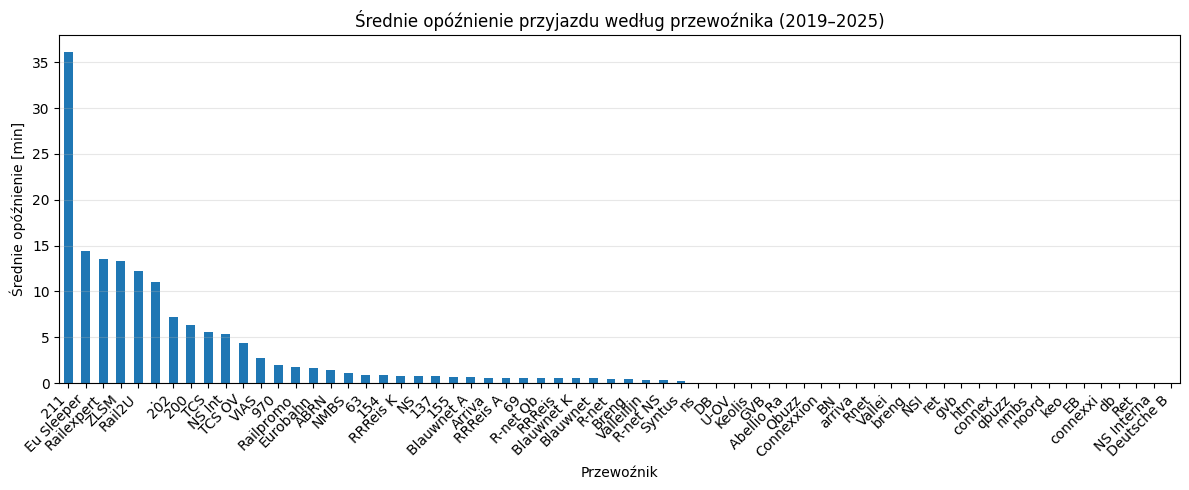

In [29]:
import matplotlib.pyplot as plt

operator_delays = db.sql("""
SELECT
    "Service:Company" AS operator,
    AVG(COALESCE("Stop:Arrival delay", 0)) AS avg_delay_minutes
FROM services
WHERE "Stop:Arrival time" IS NOT NULL
  AND NOT COALESCE("Stop:Arrival cancelled", false)
GROUP BY "Service:Company"
ORDER BY avg_delay_minutes DESC
""").df()

ax = operator_delays.plot.bar(
    x="operator",
    y="avg_delay_minutes",
    figsize=(12, 5),
    legend=False,
    title="Średnie opóźnienie przyjazdu według przewoźnika (2019–2025)",
)

ax.set_xlabel("Przewoźnik")
ax.set_ylabel("Średnie opóźnienie [min]")
ax.grid(axis="y", alpha=0.3)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### 7.8 liczba kursów z zakłóceniami według roku

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

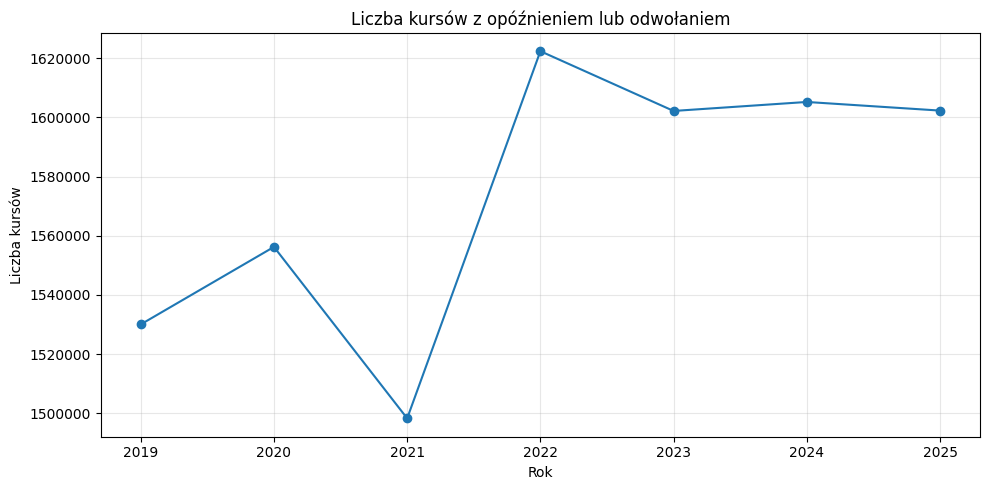

,year,disrupted_services
0,2019,1530040
1,2020,1556217
2,2021,1498298
3,2022,1622330
4,2023,1602143
5,2024,1605179
6,2025,1602266


In [31]:
db.sql("""
CREATE OR REPLACE TABLE service_summary AS
SELECT
    EXTRACT(YEAR FROM "Service:Date") AS year,
    "Service:RDT-ID" AS service_id,
    BOOL_OR(
        COALESCE("Service:Maximum delay", 0) > 0
        OR COALESCE("Service:Partly cancelled", false)
        OR COALESCE("Service:Completely cancelled", false)
    ) AS disrupted,
    BOOL_OR(
        COALESCE("Service:Completely cancelled", false)
    ) AS completely_cancelled
FROM services
GROUP BY year, service_id
""")

disrupted_by_year = db.sql("""
SELECT
    year,
    COUNT(*) FILTER (WHERE disrupted) AS disrupted_services
FROM service_summary
GROUP BY year
ORDER BY year
""").df()

ax = disrupted_by_year.plot(
    x="year",
    y="disrupted_services",
    marker="o",
    figsize=(10, 5),
    legend=False,
    title="Liczba kursów z opóźnieniem lub odwołaniem",
)

ax.set_xlabel("Rok")
ax.set_ylabel("Liczba kursów")
ax.set_xticks(disrupted_by_year["year"])
ax.ticklabel_format(axis="y", style="plain")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

disrupted_by_year

### 7.9 procent całkowicie odwołanych kursów według roku

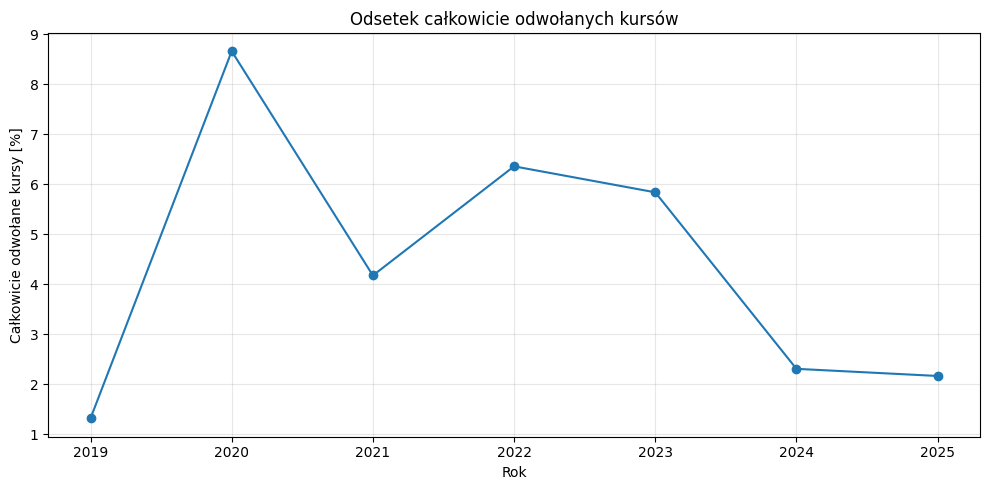

,year,total_services,cancelled_services,cancelled_percent
0,2019,2369241,31303,1.32
1,2020,2453753,212447,8.66
2,2021,2352676,98253,4.18
3,2022,2453625,155981,6.36
4,2023,2323100,135619,5.84
5,2024,2395636,55360,2.31
6,2025,2402665,52098,2.17


In [32]:
cancelled_by_year = db.sql("""
SELECT
    year,
    COUNT(*) AS total_services,
    COUNT(*) FILTER (
        WHERE completely_cancelled
    ) AS cancelled_services,
    100.0 * COUNT(*) FILTER (
        WHERE completely_cancelled
    ) / COUNT(*) AS cancelled_percent
FROM service_summary
GROUP BY year
ORDER BY year
""").df()

ax = cancelled_by_year.plot(
    x="year",
    y="cancelled_percent",
    marker="o",
    figsize=(10, 5),
    legend=False,
    title="Odsetek całkowicie odwołanych kursów",
)

ax.set_xlabel("Rok")
ax.set_ylabel("Całkowicie odwołane kursy [%]")
ax.set_xticks(cancelled_by_year["year"])
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

cancelled_by_year.round(2)

## 8. Odległości między kolejnymi stacjami

In [47]:
db.sql("""
CREATE OR REPLACE TABLE service_legs (
    "Service:RDT-ID" BIGINT,
    start_station_code VARCHAR,
    end_station_code VARCHAR
)
""")

for year in range(2019, 2026):
    print(f"Przetwarzanie {year}...", flush=True)

    db.sql(f"""
    INSERT INTO service_legs
    WITH ordered_stops AS (
        SELECT
            "Service:RDT-ID",
            "Stop:Station code" AS start_station_code,
            LEAD("Stop:Station code") OVER (
                PARTITION BY "Service:Date", "Service:RDT-ID"
                ORDER BY
                    "Stop:Departure time" NULLS LAST,
                    "Stop:Arrival time" NULLS LAST,
                    "Stop:RDT-ID"
            ) AS end_station_code
        FROM services
        WHERE "Service:Date" >= DATE '{year}-01-01'
          AND "Service:Date" < DATE '{year + 1}-01-01'
    )
    SELECT
        "Service:RDT-ID",
        start_station_code,
        end_station_code
    FROM ordered_stops
    WHERE start_station_code IS NOT NULL
      AND end_station_code IS NOT NULL
      AND start_station_code <> end_station_code
    """)

print("Odcinki gotowe")

Przetwarzanie 2019...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Przetwarzanie 2020...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Przetwarzanie 2021...


...

Przetwarzanie 2024...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Przetwarzanie 2025...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Odcinki gotowe


In [48]:
db.sql("""
CREATE OR REPLACE TABLE station_connections AS
WITH pairs AS (
    SELECT
        MIN("Service:RDT-ID") AS "Service:RDT-ID",
        start_station_code,
        end_station_code,
        COUNT(*) AS occurrences
    FROM service_legs
    GROUP BY start_station_code, end_station_code
)
SELECT
    p.*,
    d.distance
FROM pairs p
LEFT JOIN distances_long d
    ON p.start_station_code = d.Station
   AND p.end_station_code = d.other_station
""")

db.sql("""
SELECT *
FROM station_connections
LIMIT 10
""").show()

db.sql("""
SELECT
    COUNT(*) AS unique_station_pairs,
    COUNT(*) FILTER (
        WHERE distance IS NULL
    ) AS pairs_without_distance
FROM station_connections
""").show()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

┌────────────────┬────────────────────┬──────────────────┬─────────────┬──────────┐
│ Service:RDT-ID │ start_station_code │ end_station_code │ occurrences │ distance │
│     int64      │      varchar       │     varchar      │    int64    │  int64   │
├────────────────┼────────────────────┼──────────────────┼─────────────┼──────────┤
│       13180346 │ AC                 │ AMFS             │           2 │       48 │
│        9757537 │ AC                 │ APN              │           1 │       50 │
│        4209442 │ AC                 │ ASA              │          51 │        9 │
│        4492862 │ AC                 │ ASB              │         328 │        5 │
│        4965467 │ AC                 │ ASD              │          90 │       15 │
│       10290982 │ AC                 │ ASDM             │           3 │       11 │
│         738942 │ AC                 │ ASHD             │      137786 │        4 │
│        5894139 │ AC                 │ ASS              │           1 │    

In [49]:
db.sql("""
SELECT
    c.start_station_code,
    s1.name_long AS start_station,
    c.end_station_code,
    s2.name_long AS end_station,
    c.distance
FROM station_connections c
LEFT JOIN stations s1 ON c.start_station_code = s1.code
LEFT JOIN stations s2 ON c.end_station_code = s2.code
WHERE c.distance IS NOT NULL
ORDER BY c.distance DESC, c.start_station_code, c.end_station_code
LIMIT 1
""").show()

┌────────────────────┬───────────────┬──────────────────┬─────────────┬──────────┐
│ start_station_code │ start_station │ end_station_code │ end_station │ distance │
│      varchar       │    varchar    │     varchar      │   varchar   │  int64   │
├────────────────────┼───────────────┼──────────────────┼─────────────┼──────────┤
│ VS                 │ Vlissingen    │ STV              │ Stavoren    │      421 │
└────────────────────┴───────────────┴──────────────────┴─────────────┴──────────┘



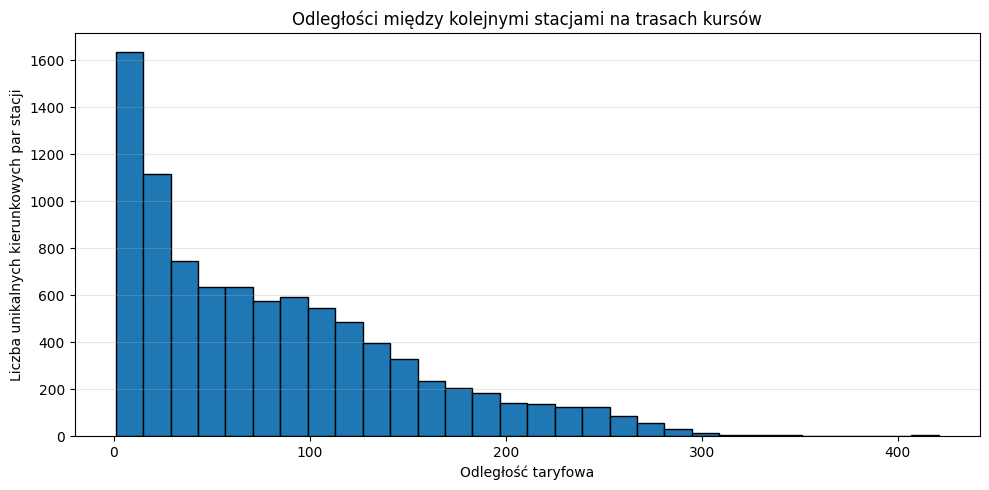

In [50]:
import matplotlib.pyplot as plt

connection_distances = db.sql("""
SELECT distance
FROM station_connections
WHERE distance IS NOT NULL
""").df()

fig, ax = plt.subplots(figsize=(10, 5))

ax.hist(
    connection_distances["distance"],
    bins=30,
    edgecolor="black",
)

ax.set_title("Odległości między kolejnymi stacjami na trasach kursów")
ax.set_xlabel("Odległość taryfowa")
ax.set_ylabel("Liczba unikalnych kierunkowych par stacji")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### Interpretacja wyników

Wyznaczono 11 399 unikalnych kierunkowych par kolejnych stacji.
Dla 9046 par dopasowano odległość taryfową, a dla 2353 brakowało
dopasowania. Histogram pokazuje przewagę krótkich odcinków.

Największa dopasowana odległość wynosi 421 dla pary
Vlissingen (VS) → Stavoren (STV).

Wynik uzyskano przez uporządkowanie postojów zgodnie z instrukcją.
W danych wykryto przypadek przeplatających się tras pod jednym
identyfikatorem kursu, dlatego maksimum należy interpretować
jako wynik analizy zbioru, a nie potwierdzony rzeczywisty odcinek.